# Local Refinement at 0.3-0.4 m

Close-range RGB/RGB-D refinement for base holes, gear grasp features/yaw, and shaft/screw grasp candidates. No ROS2 and no robot control.


base holes: 3
{'label': 'base_hole_1_left_top', 'center_u': 135.0, 'center_v': 144.0, 'area_px': 17203.36137105771, 'radius_or_bbox': 74.0, 'bbox': (61, 70, 148, 148), 'confidence_or_rule_note': 'Hough circle inside black base ROI'}
{'label': 'base_hole_2_right_top', 'center_u': 399.0, 'center_v': 303.0, 'area_px': 17671.458676442588, 'radius_or_bbox': 75.0, 'bbox': (324, 228, 150, 150), 'confidence_or_rule_note': 'Hough circle inside black base ROI'}
{'label': 'base_hole_3_lower', 'center_u': 307.0, 'center_v': 368.0, 'area_px': 18626.502843133883, 'radius_or_bbox': 77.0, 'bbox': (230, 291, 154, 154), 'confidence_or_rule_note': 'Hough circle inside black base ROI'}


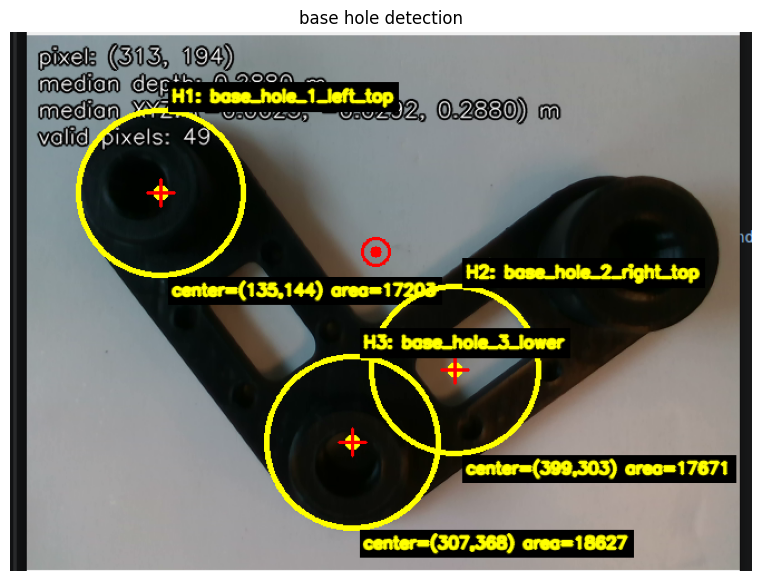

gear grasp:
{'label': 'gear_grasp', 'gear_center_2d': (350.88688448953076, 243.06199422053047), 'center_u': 350.88688448953076, 'center_v': 243.06199422053047, 'left_grasp_feature_center_2d': (306.43290957498, 243.06199422053047), 'right_grasp_feature_center_2d': (395.3408594040815, 243.06199422053047), 'grasp_midpoint_2d': (350.88688448953076, 243.06199422053047), 'grasp_yaw_image_rad': 0.0, 'grasp_yaw_image_deg': 0.0, 'gear_contour_area': 109814.0, 'confidence_or_rule_note': 'red HSV gear; grasp_features_not_reliable; geometric fallback across inner hub', 'gear_contour': array([[[332,  38]],

       [[331,  39]],

       [[328,  39]],

       ...,

       [[335,  39]],

       [[334,  39]],

       [[333,  38]]], shape=(844, 1, 2), dtype=int32), 'feature_candidates': []}


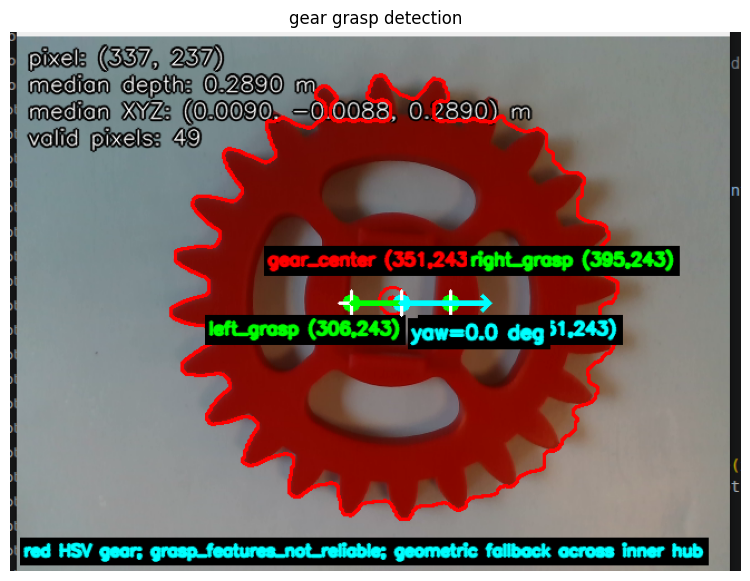

shaft/screw candidates: 3
{'label': 'Shaft_small', 'object_center_2d': (503.70855712890625, 180.04861450195312), 'center_u': 503.70855712890625, 'center_v': 180.04861450195312, 'rect_width': 231.9376983642578, 'rect_height': 114.22267150878906, 'rect_angle': -12.288323402404785, 'edge_midpoints_2d': [(390.0, 204.0), (491.0, 123.5), (616.5, 155.0), (515.5, 235.5)], 'grasp_yaw_candidates': [-0.2144717029218356, 1.356324623873061], 'bbox': (380, 115, 246, 124), 'rotated_rect': ((503.70855712890625, 180.04861450195312), (231.9376983642578, 114.22267150878906), -12.288323402404785), 'rotated_box': array([[402, 260],
       [378, 148],
       [604,  99],
       [629, 211]], dtype=int32), 'area_px': 11612.0, 'confidence_or_rule_note': 'CLAHE + Canny/adaptive threshold + minAreaRect'}
{'label': 'Screw', 'object_center_2d': (521.6560668945312, 379.4951477050781), 'center_u': 521.6560668945312, 'center_v': 379.4951477050781, 'rect_width': 58.86867904663086, 'rect_height': 60.44905090332031, 'rec

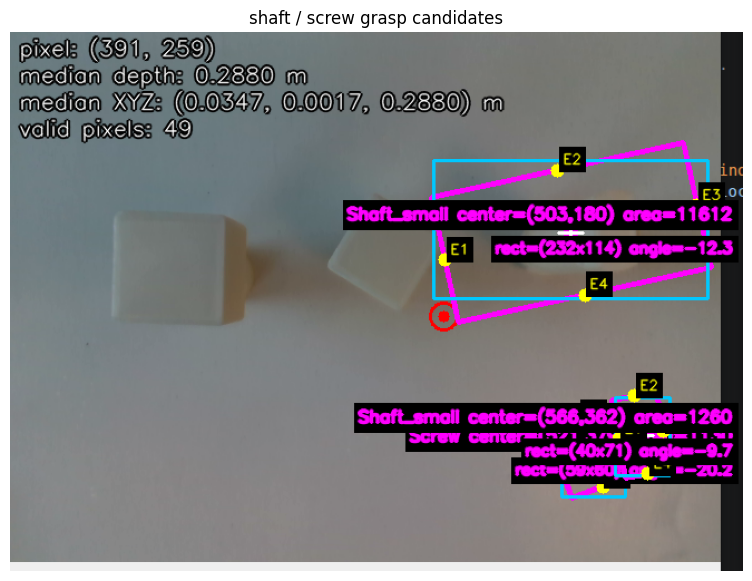

Saved CSV: /home/masais/Xinyu/local_refinement_results.csv
Global view CSV: /home/masais/Xinyu/detected_parts_2d.csv
GLOBAL {'label': 'Gear_compound', 'center_u': '303.5', 'center_v': '389.5', 'area_px': '19733.0', 'bbox_x': '222', 'bbox_y': '307', 'bbox_w': '165', 'bbox_h': '166', 'confidence_or_rule_note': 'red HSV; lower large gear rule; equiv_diameter=158.5; circularity=0.66'}
GLOBAL {'label': 'Gear_large', 'center_u': '412.5', 'center_v': '86.0', 'area_px': '22672.5', 'bbox_x': '326', 'bbox_y': '0', 'bbox_w': '176', 'bbox_h': '176', 'confidence_or_rule_note': 'red HSV; large equiv_diameter=169.9; circularity=0.65'}
GLOBAL {'label': 'Gear_small', 'center_u': '139.53', 'center_v': '118.39', 'area_px': '8175.5', 'bbox_x': '85', 'bbox_y': '65', 'bbox_w': '109', 'bbox_h': '108', 'confidence_or_rule_note': 'red HSV; small equiv_diameter=102.0; circularity=0.66'}
GLOBAL {'label': 'Screw', 'center_u': '301.5', 'center_v': '91.5', 'area_px': '164.0', 'bbox_x': '290', 'bbox_y': '86', 'bbox_

In [1]:
# %% [markdown]
# # Local Refinement at 0.3-0.4 m
#
# This notebook performs close-range RGB/RGB-D refinement only. It does not use ROS2 and does not command a robot.

# =========================
# Part 1: imports and global parameters
# =========================
from pathlib import Path
import math
import time
import csv

import cv2
import matplotlib.pyplot as plt
import numpy as np

try:
    import pyrealsense2 as rs
    REALSENSE_AVAILABLE = True
except ImportError:
    rs = None
    REALSENSE_AVAILABLE = False

BASE_IMAGE_PATH = "realsense_pic/base_0.4.png"
GEAR_IMAGE_PATH = "realsense_pic/Gear_0.4.png"
SHAFT_SCREW_IMAGE_PATH = "realsense_pic/Shaft+screw_0.4.png"
GLOBAL_CSV_PATH = "detected_parts_2d.csv"
LOCAL_RESULT_CSV_PATH = "local_refinement_results.csv"
LOCAL_RESULT_IMAGE_DIR = "local_refinement_results"

# Saved files are screenshots containing left RGB view and right depth colormap view.
# If you later save pure RGB frames, set CROP_REALSENSE_SCREENSHOT = False.
CROP_REALSENSE_SCREENSHOT = True
SCREENSHOT_RGB_X0 = 0
SCREENSHOT_RGB_X1_RATIO = 0.50
SCREENSHOT_RGB_Y0 = 76
SCREENSHOT_RGB_BOTTOM_MARGIN = 18

# Color/shape thresholds, intentionally easy to tune.
RED_HSV_LOWER_1 = np.array([0, 70, 40])
RED_HSV_UPPER_1 = np.array([12, 255, 255])
RED_HSV_LOWER_2 = np.array([165, 70, 40])
RED_HSV_UPPER_2 = np.array([179, 255, 255])
RED_OPEN_KERNEL = 5
RED_CLOSE_KERNEL = 11
GEAR_MIN_AREA = 6000
GEAR_CENTER_ROI_RATIO = 0.42
GEAR_FEATURE_MIN_AREA = 250
GEAR_FEATURE_MAX_AREA = 12000
GEAR_FEATURE_MIN_ASPECT = 0.35
GEAR_FEATURE_MAX_ASPECT = 3.0

BLACK_HSV_LOWER = np.array([0, 0, 0])
BLACK_HSV_UPPER = np.array([179, 255, 95])
BASE_MIN_AREA = 8000
BASE_OPEN_KERNEL = 5
BASE_CLOSE_KERNEL = 17
BASE_HOLE_MIN_AREA = 500
BASE_HOLE_MAX_AREA = 25000
BASE_HOLE_MIN_CIRCULARITY = 0.25
BASE_HOLE_HOUGH_DP = 1.2
BASE_HOLE_HOUGH_MIN_DIST = 80
BASE_HOLE_HOUGH_PARAM1 = 70
BASE_HOLE_HOUGH_PARAM2 = 18
BASE_HOLE_MIN_RADIUS = 12
BASE_HOLE_MAX_RADIUS = 80

WHITE_MIN_AREA = 700
WHITE_MAX_AREA = 35000
WHITE_MIN_W = 20
WHITE_MIN_H = 20
WHITE_CANNY_LOW = 25
WHITE_CANNY_HIGH = 95
WHITE_ADAPTIVE_BLOCK_SIZE = 41
WHITE_ADAPTIVE_C = 3
WHITE_CLOSE_KERNEL = 9
WHITE_DILATE_KERNEL = 3
SHAFT_SCREW_IGNORE_TOP_PIXELS = 115
SHAFT_SCREW_MAX_BBOX_AREA_RATIO = 0.18
SHAFT_SCREW_MAX_LONG_SIDE = 260

DEPTH_MEDIAN_WINDOW = 7
LIVE_WIDTH = 640
LIVE_HEIGHT = 480
LIVE_FPS = 30

DRAW_COLORS = {
    "base_hole": (0, 255, 255),
    "gear": (0, 0, 255),
    "gear_grasp": (0, 255, 0),
    "shaft_screw": (255, 0, 255),
    "unknown": (255, 160, 0),
}

Path(LOCAL_RESULT_IMAGE_DIR).mkdir(exist_ok=True)


def show_bgr(image, title="image", figsize=(10, 7)):
    plt.figure(figsize=figsize)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


def load_local_test_image(image_path, crop_realsense_screenshot=CROP_REALSENSE_SCREENSHOT):
    image = cv2.imread(str(image_path), cv2.IMREAD_COLOR)
    if image is None:
        raise FileNotFoundError(f"Could not read image: {Path(image_path).resolve()}")
    if not crop_realsense_screenshot:
        return image
    h, w = image.shape[:2]
    x0 = int(SCREENSHOT_RGB_X0)
    x1 = int(w * SCREENSHOT_RGB_X1_RATIO)
    y0 = min(int(SCREENSHOT_RGB_Y0), h - 1)
    y1 = max(y0 + 1, h - int(SCREENSHOT_RGB_BOTTOM_MARGIN))
    return image[y0:y1, x0:x1].copy()


# =========================
# Part 2: RealSense aligned RGB-D capture utilities
# =========================
def start_realsense_pipeline(width=LIVE_WIDTH, height=LIVE_HEIGHT, fps=LIVE_FPS):
    if not REALSENSE_AVAILABLE:
        raise RuntimeError("pyrealsense2 is not installed. Offline RGB mode still works.")
    pipeline = rs.pipeline()
    config = rs.config()
    config.enable_stream(rs.stream.color, width, height, rs.format.bgr8, fps)
    config.enable_stream(rs.stream.depth, width, height, rs.format.z16, fps)
    profile = pipeline.start(config)
    align = rs.align(rs.stream.color)
    depth_scale = profile.get_device().first_depth_sensor().get_depth_scale()
    intrinsics = profile.get_stream(rs.stream.color).as_video_stream_profile().get_intrinsics()
    return pipeline, align, depth_scale, intrinsics


def capture_aligned_rgbd(pipeline, align, warmup=5):
    if not REALSENSE_AVAILABLE:
        raise RuntimeError("pyrealsense2 is not installed.")
    frames = None
    for _ in range(max(1, warmup)):
        frames = pipeline.wait_for_frames()
    aligned = align.process(frames)
    depth_frame = aligned.get_depth_frame()
    color_frame = aligned.get_color_frame()
    if not depth_frame or not color_frame:
        raise RuntimeError("Could not capture aligned color/depth frames.")
    color_image = np.asanyarray(color_frame.get_data()).copy()
    depth_image = np.asanyarray(depth_frame.get_data()).copy()
    depth_colormap = cv2.applyColorMap(
        cv2.convertScaleAbs(depth_image, alpha=0.03), cv2.COLORMAP_JET
    )
    return color_image, depth_frame, depth_image, depth_colormap


def get_median_depth_around_pixel(depth_frame, u, v, window_size=7):
    if depth_frame is None:
        return None, 0
    half = int(window_size) // 2
    u = int(round(u))
    v = int(round(v))

    # RealSense frame API path.
    if hasattr(depth_frame, "get_width") and hasattr(depth_frame, "get_distance"):
        width = depth_frame.get_width()
        height = depth_frame.get_height()
        x0, x1 = max(0, u - half), min(width - 1, u + half)
        y0, y1 = max(0, v - half), min(height - 1, v + half)
        values = []
        for yy in range(y0, y1 + 1):
            for xx in range(x0, x1 + 1):
                d = float(depth_frame.get_distance(xx, yy))
                if np.isfinite(d) and d > 0:
                    values.append(d)
    else:
        depth_image = np.asarray(depth_frame)
        height, width = depth_image.shape[:2]
        x0, x1 = max(0, u - half), min(width, u + half + 1)
        y0, y1 = max(0, v - half), min(height, v + half + 1)
        patch = depth_image[y0:y1, x0:x1].astype(np.float32).reshape(-1)
        # If the array looks like uint16 RealSense depth, caller should pass meters or scale it first.
        values = patch[np.isfinite(patch) & (patch > 0)]

    if len(values) == 0:
        return None, 0
    values = np.asarray(values, dtype=np.float32)
    return float(np.median(values)), int(values.size)


def deproject_pixel_to_3d(intrinsics, u, v, depth_m):
    if intrinsics is None or depth_m is None or depth_m <= 0:
        return None
    if not REALSENSE_AVAILABLE:
        return None
    point = rs.rs2_deproject_pixel_to_point(intrinsics, [float(u), float(v)], float(depth_m))
    return tuple(float(x) for x in point)


def add_depth_3d_fields(result, depth_frame=None, intrinsics=None, u_key="center_u", v_key="center_v", prefix="center"):
    if depth_frame is None:
        return result
    depth_m, valid = get_median_depth_around_pixel(depth_frame, result[u_key], result[v_key], DEPTH_MEDIAN_WINDOW)
    result[f"{prefix}_depth_m"] = depth_m
    result[f"{prefix}_depth_valid_count"] = valid
    result[f"{prefix}_3d"] = deproject_pixel_to_3d(intrinsics, result[u_key], result[v_key], depth_m)
    return result


# =========================
# Part 3: color threshold and preprocessing utilities
# =========================
def morph(mask, open_kernel=0, close_kernel=0, dilate_kernel=0, iterations=1):
    out = mask.copy()
    if open_kernel and open_kernel > 1:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (open_kernel, open_kernel))
        out = cv2.morphologyEx(out, cv2.MORPH_OPEN, k, iterations=iterations)
    if close_kernel and close_kernel > 1:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (close_kernel, close_kernel))
        out = cv2.morphologyEx(out, cv2.MORPH_CLOSE, k, iterations=iterations)
    if dilate_kernel and dilate_kernel > 1:
        k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (dilate_kernel, dilate_kernel))
        out = cv2.dilate(out, k, iterations=iterations)
    return out


def red_mask(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    m1 = cv2.inRange(hsv, RED_HSV_LOWER_1, RED_HSV_UPPER_1)
    m2 = cv2.inRange(hsv, RED_HSV_LOWER_2, RED_HSV_UPPER_2)
    mask = cv2.bitwise_or(m1, m2)
    return morph(mask, RED_OPEN_KERNEL, RED_CLOSE_KERNEL, 0, iterations=1)


def black_mask(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, BLACK_HSV_LOWER, BLACK_HSV_UPPER)
    return morph(mask, BASE_OPEN_KERNEL, BASE_CLOSE_KERNEL, 0, iterations=1)


def contour_center(contour):
    m = cv2.moments(contour)
    if abs(m["m00"]) > 1e-6:
        return float(m["m10"] / m["m00"]), float(m["m01"] / m["m00"])
    x, y, w, h = cv2.boundingRect(contour)
    return float(x + w / 2), float(y + h / 2)


def circularity(contour):
    area = cv2.contourArea(contour)
    peri = cv2.arcLength(contour, True)
    if peri <= 1e-6:
        return 0.0
    return float(4 * math.pi * area / (peri * peri))


def box_points_int(rect):
    return cv2.boxPoints(rect).astype(np.int32)


def edge_midpoints_from_box(box):
    pts = box.astype(np.float32)
    mids = []
    for i in range(4):
        p1 = pts[i]
        p2 = pts[(i + 1) % 4]
        mids.append(((float(p1[0] + p2[0]) / 2.0), (float(p1[1] + p2[1]) / 2.0)))
    return mids


# =========================
# Part 4: base hole detection
# =========================
def sort_base_holes(hole_results):
    if len(hole_results) < 3:
        return hole_results
    holes = sorted(hole_results, key=lambda r: r["center_v"])
    top_two = sorted(holes[:2], key=lambda r: r["center_u"])
    lower = sorted(holes[2:], key=lambda r: r["center_v"], reverse=True)[0]
    ordered = [top_two[0], top_two[1], lower]
    labels = ["base_hole_1_left_top", "base_hole_2_right_top", "base_hole_3_lower"]
    for label, item in zip(labels, ordered):
        item["label"] = label
    return ordered


def detect_base_holes(color_image, depth_frame=None, intrinsics=None):
    gray = cv2.cvtColor(color_image, cv2.COLOR_BGR2GRAY)
    base_mask = black_mask(color_image)
    contours, _ = cv2.findContours(base_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return [], {"base_mask": base_mask}
    base_contour = max(contours, key=cv2.contourArea)
    base_area = cv2.contourArea(base_contour)
    if base_area < BASE_MIN_AREA:
        return [], {"base_mask": base_mask}

    roi_mask = np.zeros(gray.shape, dtype=np.uint8)
    cv2.drawContours(roi_mask, [base_contour], -1, 255, cv2.FILLED)
    x, y, w, h = cv2.boundingRect(base_contour)
    roi_gray = gray[y:y + h, x:x + w]
    roi_base = roi_mask[y:y + h, x:x + w]

    # Holes are dark circular structures inside the black base. Hough detects the rims well in close view.
    blur = cv2.GaussianBlur(roi_gray, (9, 9), 1.5)
    circles = cv2.HoughCircles(
        blur,
        cv2.HOUGH_GRADIENT,
        dp=BASE_HOLE_HOUGH_DP,
        minDist=BASE_HOLE_HOUGH_MIN_DIST,
        param1=BASE_HOLE_HOUGH_PARAM1,
        param2=BASE_HOLE_HOUGH_PARAM2,
        minRadius=BASE_HOLE_MIN_RADIUS,
        maxRadius=BASE_HOLE_MAX_RADIUS,
    )

    results = []
    if circles is not None:
        circles = np.round(circles[0, :]).astype(int)
        for cx, cy, radius in circles:
            u, v = x + int(cx), y + int(cy)
            if not (0 <= u < gray.shape[1] and 0 <= v < gray.shape[0]):
                continue
            if roi_mask[v, u] == 0:
                continue
            area_px = math.pi * float(radius) * float(radius)
            if not (BASE_HOLE_MIN_AREA <= area_px <= BASE_HOLE_MAX_AREA):
                continue
            item = {
                "label": "base_hole_candidate",
                "center_u": float(u),
                "center_v": float(v),
                "area_px": float(area_px),
                "radius_or_bbox": float(radius),
                "bbox": (int(u - radius), int(v - radius), int(2 * radius), int(2 * radius)),
                "confidence_or_rule_note": "Hough circle inside black base ROI",
            }
            add_depth_3d_fields(item, depth_frame, intrinsics)
            results.append(item)

    # Fallback contour path: useful when Hough is too strict or depth holes are invalid.
    if len(results) < 3:
        edges = cv2.Canny(blur, 40, 120)
        edges = cv2.bitwise_and(edges, roi_base)
        edges = morph(edges, 0, 7, 3, iterations=1)
        hole_contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        for contour in hole_contours:
            area = cv2.contourArea(contour)
            if not (BASE_HOLE_MIN_AREA <= area <= BASE_HOLE_MAX_AREA):
                continue
            circ = circularity(contour)
            if circ < BASE_HOLE_MIN_CIRCULARITY:
                continue
            (cx, cy), radius = cv2.minEnclosingCircle(contour)
            u, v = x + cx, y + cy
            if roi_mask[int(round(v)), int(round(u))] == 0:
                continue
            if any(math.hypot(u - r["center_u"], v - r["center_v"]) < 35 for r in results):
                continue
            item = {
                "label": "base_hole_candidate",
                "center_u": float(u),
                "center_v": float(v),
                "area_px": float(area),
                "radius_or_bbox": float(radius),
                "bbox": (int(u - radius), int(v - radius), int(2 * radius), int(2 * radius)),
                "confidence_or_rule_note": f"edge contour fallback; circularity={circ:.2f}",
            }
            add_depth_3d_fields(item, depth_frame, intrinsics)
            results.append(item)

    results = sorted(results, key=lambda r: r["area_px"], reverse=True)[:3]
    results = sort_base_holes(results)
    debug = {"base_mask": base_mask, "roi_mask": roi_mask, "base_contour": base_contour}
    return results, debug


# =========================
# Part 5: gear grasp point and yaw detection
# =========================
def detect_gear_grasp(color_image, depth_frame=None, intrinsics=None):
    mask = red_mask(color_image)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    contours = [c for c in contours if cv2.contourArea(c) >= GEAR_MIN_AREA]
    if not contours:
        return None, {"red_mask": mask}
    gear_contour = max(contours, key=cv2.contourArea)
    gear_area = float(cv2.contourArea(gear_contour))
    gear_u, gear_v = contour_center(gear_contour)
    (_, _), radius = cv2.minEnclosingCircle(gear_contour)

    # Avoid outer teeth: search only in a center ROI and look for red connected features.
    center_roi = np.zeros(mask.shape, dtype=np.uint8)
    roi_radius = max(20, int(radius * GEAR_CENTER_ROI_RATIO))
    cv2.circle(center_roi, (int(round(gear_u)), int(round(gear_v))), roi_radius, 255, cv2.FILLED)
    inner_red = cv2.bitwise_and(mask, center_roi)
    inner_red = morph(inner_red, 3, 9, 0, iterations=1)

    inner_contours, _ = cv2.findContours(inner_red, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    feature_candidates = []
    for c in inner_contours:
        area = cv2.contourArea(c)
        if not (GEAR_FEATURE_MIN_AREA <= area <= GEAR_FEATURE_MAX_AREA):
            continue
        x, y, w, h = cv2.boundingRect(c)
        aspect = w / max(1, h)
        if not (GEAR_FEATURE_MIN_ASPECT <= aspect <= GEAR_FEATURE_MAX_ASPECT):
            continue
        cx, cy = contour_center(c)
        # Keep candidates near center but offset left/right from gear center.
        dist = math.hypot(cx - gear_u, cy - gear_v)
        if dist > roi_radius:
            continue
        feature_candidates.append({"contour": c, "center": (cx, cy), "area": area, "bbox": (x, y, w, h)})

    left_feature = None
    right_feature = None
    note = "red HSV gear; "
    if len(feature_candidates) >= 2:
        left_side = [f for f in feature_candidates if f["center"][0] < gear_u]
        right_side = [f for f in feature_candidates if f["center"][0] >= gear_u]
        if left_side and right_side:
            left_feature = max(left_side, key=lambda f: f["area"])
            right_feature = max(right_side, key=lambda f: f["area"])
            note += "inner red connected components used for grasp features"

    if left_feature is None or right_feature is None:
        # Geometric fallback: choose two points across the central red hub, not the outer teeth.
        offset = radius * 0.22
        left_feature = {"center": (gear_u - offset, gear_v), "area": 0, "bbox": None, "contour": None}
        right_feature = {"center": (gear_u + offset, gear_v), "area": 0, "bbox": None, "contour": None}
        note += "grasp_features_not_reliable; geometric fallback across inner hub"

    lu, lv = left_feature["center"]
    ru, rv = right_feature["center"]
    midpoint_u = (lu + ru) / 2.0
    midpoint_v = (lv + rv) / 2.0
    yaw = math.atan2(rv - lv, ru - lu)

    result = {
        "label": "gear_grasp",
        "gear_center_2d": (float(gear_u), float(gear_v)),
        "center_u": float(gear_u),
        "center_v": float(gear_v),
        "left_grasp_feature_center_2d": (float(lu), float(lv)),
        "right_grasp_feature_center_2d": (float(ru), float(rv)),
        "grasp_midpoint_2d": (float(midpoint_u), float(midpoint_v)),
        "grasp_yaw_image_rad": float(yaw),
        "grasp_yaw_image_deg": float(math.degrees(yaw)),
        "gear_contour_area": gear_area,
        "confidence_or_rule_note": note,
        "gear_contour": gear_contour,
        "feature_candidates": feature_candidates,
    }

    if depth_frame is not None:
        depth_m, valid = get_median_depth_around_pixel(depth_frame, midpoint_u, midpoint_v, DEPTH_MEDIAN_WINDOW)
        result["grasp_midpoint_depth_m"] = depth_m
        result["grasp_midpoint_depth_valid_count"] = valid
        result["grasp_midpoint_3d"] = deproject_pixel_to_3d(intrinsics, midpoint_u, midpoint_v, depth_m)
        depth_m, valid = get_median_depth_around_pixel(depth_frame, gear_u, gear_v, DEPTH_MEDIAN_WINDOW)
        result["gear_center_depth_m"] = depth_m
        result["gear_center_depth_valid_count"] = valid
        result["gear_center_3d"] = deproject_pixel_to_3d(intrinsics, gear_u, gear_v, depth_m)

    debug = {"red_mask": mask, "inner_red": inner_red, "gear_contour": gear_contour}
    return result, debug


# =========================
# Part 6: shaft / screw grasp candidate detection
# =========================
def classify_shaft_screw(area, rect_w, rect_h):
    long_side = max(rect_w, rect_h)
    short_side = max(1.0, min(rect_w, rect_h))
    aspect = long_side / short_side
    if aspect >= 2.4 and long_side >= 95:
        return "Shaft_large"
    if aspect >= 1.7 and long_side >= 55:
        return "Shaft_small"
    if area < 5000 and long_side < 85:
        return "Screw"
    return "unknown_shaft_or_screw"


def detect_shaft_screw_grasp_candidates(color_image, depth_frame=None, intrinsics=None):
    gray = cv2.cvtColor(color_image, cv2.COLOR_BGR2GRAY)
    lab = cv2.cvtColor(color_image, cv2.COLOR_BGR2LAB)
    l_channel = lab[:, :, 0]
    clahe = cv2.createCLAHE(clipLimit=2.5, tileGridSize=(8, 8))
    enhanced = clahe.apply(l_channel)
    blur = cv2.GaussianBlur(enhanced, (5, 5), 0)
    edges = cv2.Canny(blur, WHITE_CANNY_LOW, WHITE_CANNY_HIGH)

    block = WHITE_ADAPTIVE_BLOCK_SIZE + (WHITE_ADAPTIVE_BLOCK_SIZE % 2 == 0)
    adaptive = cv2.adaptiveThreshold(
        blur, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY_INV, block, WHITE_ADAPTIVE_C
    )
    mask = cv2.bitwise_or(edges, adaptive)
    mask[:SHAFT_SCREW_IGNORE_TOP_PIXELS, :] = 0
    mask = morph(mask, 0, WHITE_CLOSE_KERNEL, WHITE_DILATE_KERNEL, iterations=1)

    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    results = []
    for contour in contours:
        area = float(cv2.contourArea(contour))
        if not (WHITE_MIN_AREA <= area <= WHITE_MAX_AREA):
            continue
        rect = cv2.minAreaRect(contour)
        (cx, cy), (rw, rh), angle = rect
        if rw < WHITE_MIN_W or rh < WHITE_MIN_H:
            if max(rw, rh) < WHITE_MIN_W or min(rw, rh) < 8:
                continue
        box = box_points_int(rect)
        x, y, w, h = cv2.boundingRect(contour)
        image_h, image_w = gray.shape[:2]
        bbox_area_ratio = (w * h) / float(image_w * image_h)
        if bbox_area_ratio > SHAFT_SCREW_MAX_BBOX_AREA_RATIO:
            continue
        if max(rw, rh) > SHAFT_SCREW_MAX_LONG_SIDE:
            continue
        if x <= 1 or y <= SHAFT_SCREW_IGNORE_TOP_PIXELS - 2 or x + w >= image_w - 1 or y + h >= image_h - 1:
            continue
        edge_midpoints = edge_midpoints_from_box(box)
        long_side = max(rw, rh)
        short_side = max(1.0, min(rw, rh))
        # Candidate grasp yaw directions: along long axis and short axis.
        yaw_long = math.radians(angle if rw >= rh else angle + 90)
        yaw_short = yaw_long + math.pi / 2.0
        label = classify_shaft_screw(area, rw, rh)
        item = {
            "label": label,
            "object_center_2d": (float(cx), float(cy)),
            "center_u": float(cx),
            "center_v": float(cy),
            "rect_width": float(rw),
            "rect_height": float(rh),
            "rect_angle": float(angle),
            "edge_midpoints_2d": edge_midpoints,
            "grasp_yaw_candidates": [float(yaw_long), float(yaw_short)],
            "bbox": (int(x), int(y), int(w), int(h)),
            "rotated_rect": rect,
            "rotated_box": box,
            "area_px": area,
            "confidence_or_rule_note": "CLAHE + Canny/adaptive threshold + minAreaRect",
        }
        add_depth_3d_fields(item, depth_frame, intrinsics, prefix="object_center")
        if depth_frame is not None:
            midpoints_3d = []
            for mu, mv in edge_midpoints:
                d, valid = get_median_depth_around_pixel(depth_frame, mu, mv, DEPTH_MEDIAN_WINDOW)
                midpoints_3d.append({"point_2d": (mu, mv), "depth_m": d, "valid_count": valid, "point_3d": deproject_pixel_to_3d(intrinsics, mu, mv, d)})
            item["edge_midpoints_3d"] = midpoints_3d
        results.append(item)

    return sorted(results, key=lambda r: r["center_u"]), {"white_candidate_mask": mask}


# =========================
# Part 7: visualization
# =========================
def draw_label(image, text, anchor, color, scale=0.55, thickness=2):
    x, y = int(anchor[0]), int(anchor[1])
    h, w = image.shape[:2]
    (tw, th), baseline = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, thickness)
    x = max(4, min(x, w - tw - 8))
    y = max(th + 6, min(y, h - baseline - 6))
    cv2.rectangle(image, (x - 3, y - th - 5), (x + tw + 3, y + baseline + 3), (0, 0, 0), -1)
    cv2.putText(image, text, (x, y), cv2.FONT_HERSHEY_SIMPLEX, scale, color, thickness, cv2.LINE_AA)


def draw_base_holes(image, holes):
    out = image.copy()
    for idx, item in enumerate(holes, start=1):
        u, v = int(round(item["center_u"])), int(round(item["center_v"]))
        radius = int(round(item.get("radius_or_bbox", 18)))
        color = DRAW_COLORS["base_hole"]
        cv2.circle(out, (u, v), radius, color, 3)
        cv2.circle(out, (u, v), 7, color, -1)
        cv2.drawMarker(out, (u, v), (0, 0, 255), cv2.MARKER_CROSS, 24, 2)
        short_name = f"H{idx}"
        draw_label(out, f"{short_name}: {item['label']}", (u + 10, v - radius - 8), color, scale=0.5)
        draw_label(out, f"center=({u},{v}) area={item['area_px']:.0f}", (u + 10, v + radius + 18), color, scale=0.48)
    return out


def draw_gear_grasp(image, result):
    out = image.copy()
    if result is None:
        return out
    contour = result.get("gear_contour")
    if contour is not None:
        cv2.drawContours(out, [contour], -1, DRAW_COLORS["gear"], 2)
    gu, gv = result["gear_center_2d"]
    lu, lv = result["left_grasp_feature_center_2d"]
    ru, rv = result["right_grasp_feature_center_2d"]
    mu, mv = result["grasp_midpoint_2d"]
    gear_points = [
        ((gu, gv), DRAW_COLORS["gear"], "gear_center", (-120, -34)),
        ((lu, lv), DRAW_COLORS["gear_grasp"], "left_grasp", (-128, 28)),
        ((ru, rv), DRAW_COLORS["gear_grasp"], "right_grasp", (18, -34)),
        ((mu, mv), (255, 255, 0), "grasp_mid", (18, 28)),
    ]
    for p, color, name, offset in gear_points:
        u, v = int(round(p[0])), int(round(p[1]))
        cv2.circle(out, (u, v), 8, color, -1)
        cv2.drawMarker(out, (u, v), (255, 255, 255), cv2.MARKER_CROSS, 22, 2)
        draw_label(out, f"{name} ({u},{v})", (u + offset[0], v + offset[1]), color, scale=0.52)
    cv2.line(out, (int(lu), int(lv)), (int(ru), int(rv)), DRAW_COLORS["gear_grasp"], 3)
    yaw = result["grasp_yaw_image_rad"]
    length = 80
    cv2.arrowedLine(out, (int(mu), int(mv)), (int(mu + length * math.cos(yaw)), int(mv + length * math.sin(yaw))), (255, 255, 0), 3)
    draw_label(out, f"yaw={result['grasp_yaw_image_deg']:.1f} deg", (int(mu) + 10, int(mv) + 32), (255, 255, 0), scale=0.58)
    draw_label(out, result.get("confidence_or_rule_note", ""), (12, out.shape[0] - 14), (255, 255, 0), scale=0.48)
    return out


def draw_shaft_screw_candidates(image, results):
    out = image.copy()
    for item in results:
        box = item["rotated_box"]
        color = DRAW_COLORS["shaft_screw"]
        cv2.polylines(out, [box], True, color, 3)
        if "bbox" in item:
            x, y, w, h = item["bbox"]
            cv2.rectangle(out, (x, y), (x + w, y + h), (255, 200, 0), 2)
        cx, cy = item["object_center_2d"]
        cv2.circle(out, (int(cx), int(cy)), 7, color, -1)
        cv2.drawMarker(out, (int(cx), int(cy)), (255, 255, 255), cv2.MARKER_CROSS, 22, 2)
        for edge_idx, (mu, mv) in enumerate(item["edge_midpoints_2d"], start=1):
            cv2.circle(out, (int(round(mu)), int(round(mv))), 6, (0, 255, 255), -1)
            draw_label(out, f"E{edge_idx}", (int(mu) + 5, int(mv) - 5), (0, 255, 255), scale=0.42, thickness=1)
        label = f"{item['label']} center=({int(cx)},{int(cy)}) area={item['area_px']:.0f}"
        draw_label(out, label, (int(cx) + 10, int(cy) - 12), color, scale=0.5)
        draw_label(out, f"rect=({item['rect_width']:.0f}x{item['rect_height']:.0f}) angle={item['rect_angle']:.1f}", (int(cx) + 10, int(cy) + 18), color, scale=0.45)
    return out


def save_local_results_csv(rows, csv_path=LOCAL_RESULT_CSV_PATH):
    fieldnames = ["source", "label", "center_u", "center_v", "area_px", "bbox", "yaw_deg", "note"]
    with open(csv_path, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=fieldnames)
        writer.writeheader()
        for row in rows:
            writer.writerow({name: row.get(name, "") for name in fieldnames})
    print(f"Saved CSV: {Path(csv_path).resolve()}")


# =========================
# Part 8: test on saved images
# =========================
def run_base_offline_test(image_path=BASE_IMAGE_PATH):
    image = load_local_test_image(image_path)
    holes, debug = detect_base_holes(image)
    vis = draw_base_holes(image, holes)
    out_path = Path(LOCAL_RESULT_IMAGE_DIR) / "base_holes_result.png"
    cv2.imwrite(str(out_path), vis)
    print(f"base holes: {len(holes)}")
    for h in holes:
        print(h)
    show_bgr(vis, "base hole detection")
    return holes, vis, debug


def run_gear_offline_test(image_path=GEAR_IMAGE_PATH):
    image = load_local_test_image(image_path)
    result, debug = detect_gear_grasp(image)
    vis = draw_gear_grasp(image, result)
    out_path = Path(LOCAL_RESULT_IMAGE_DIR) / "gear_grasp_result.png"
    cv2.imwrite(str(out_path), vis)
    print("gear grasp:")
    print(result)
    show_bgr(vis, "gear grasp detection")
    return result, vis, debug


def run_shaft_screw_offline_test(image_path=SHAFT_SCREW_IMAGE_PATH):
    image = load_local_test_image(image_path)
    results, debug = detect_shaft_screw_grasp_candidates(image)
    vis = draw_shaft_screw_candidates(image, results)
    out_path = Path(LOCAL_RESULT_IMAGE_DIR) / "shaft_screw_result.png"
    cv2.imwrite(str(out_path), vis)
    print(f"shaft/screw candidates: {len(results)}")
    for r in results:
        print(r)
    show_bgr(vis, "shaft / screw grasp candidates")
    return results, vis, debug


def run_all_offline_tests(save_csv=True):
    all_rows = []
    base_holes, _, _ = run_base_offline_test()
    for item in base_holes:
        all_rows.append({"source": BASE_IMAGE_PATH, "label": item["label"], "center_u": round(item["center_u"], 2), "center_v": round(item["center_v"], 2), "area_px": round(item["area_px"], 1), "bbox": item.get("bbox"), "note": item.get("confidence_or_rule_note")})

    gear_result, _, _ = run_gear_offline_test()
    if gear_result:
        mu, mv = gear_result["grasp_midpoint_2d"]
        all_rows.append({"source": GEAR_IMAGE_PATH, "label": "gear_grasp_midpoint", "center_u": round(mu, 2), "center_v": round(mv, 2), "area_px": round(gear_result["gear_contour_area"], 1), "bbox": "", "yaw_deg": round(gear_result["grasp_yaw_image_deg"], 2), "note": gear_result["confidence_or_rule_note"]})

    shaft_results, _, _ = run_shaft_screw_offline_test()
    for item in shaft_results:
        all_rows.append({"source": SHAFT_SCREW_IMAGE_PATH, "label": item["label"], "center_u": round(item["center_u"], 2), "center_v": round(item["center_v"], 2), "area_px": round(item["area_px"], 1), "bbox": item.get("bbox"), "yaw_deg": round(math.degrees(item["grasp_yaw_candidates"][0]), 2), "note": item.get("confidence_or_rule_note")})

    if save_csv:
        save_local_results_csv(all_rows)
    return all_rows


# =========================
# Part 9: optional live RealSense test
# =========================
def run_live_realsense_once(mode="gear"):
    if not REALSENSE_AVAILABLE:
        raise RuntimeError("pyrealsense2 is not installed. Install it or use offline image tests.")
    pipeline, align, depth_scale, intrinsics = start_realsense_pipeline()
    try:
        color_image, depth_frame, depth_image, depth_colormap = capture_aligned_rgbd(pipeline, align)
        if mode == "base":
            result, _ = detect_base_holes(color_image, depth_frame, intrinsics)
            vis = draw_base_holes(color_image, result)
        elif mode == "shaft_screw":
            result, _ = detect_shaft_screw_grasp_candidates(color_image, depth_frame, intrinsics)
            vis = draw_shaft_screw_candidates(color_image, result)
        else:
            result, _ = detect_gear_grasp(color_image, depth_frame, intrinsics)
            vis = draw_gear_grasp(color_image, result)
        combined = np.hstack([vis, depth_colormap])
        show_bgr(combined, f"live RealSense {mode}: RGB detection + depth colormap", figsize=(14, 7))
        return result, combined
    finally:
        pipeline.stop()


# =========================
# Part 10: compare global and local view results
# =========================
def compare_global_and_local(global_csv_path=GLOBAL_CSV_PATH, local_csv_path=LOCAL_RESULT_CSV_PATH):
    print("Global view CSV:", Path(global_csv_path).resolve())
    if Path(global_csv_path).exists():
        with open(global_csv_path, newline="", encoding="utf-8") as f:
            for row in csv.DictReader(f):
                print("GLOBAL", row)
    else:
        print("Global CSV not found. Run x.ipynb first if needed.")

    print("\nLocal refinement CSV:", Path(local_csv_path).resolve())
    if Path(local_csv_path).exists():
        with open(local_csv_path, newline="", encoding="utf-8") as f:
            for row in csv.DictReader(f):
                print("LOCAL ", row)
    else:
        print("Local CSV not found. Run run_all_offline_tests() first.")


# Run all saved-image tests by default. Comment this out if you only want to import functions.
all_local_results = run_all_offline_tests()
compare_global_and_local()
